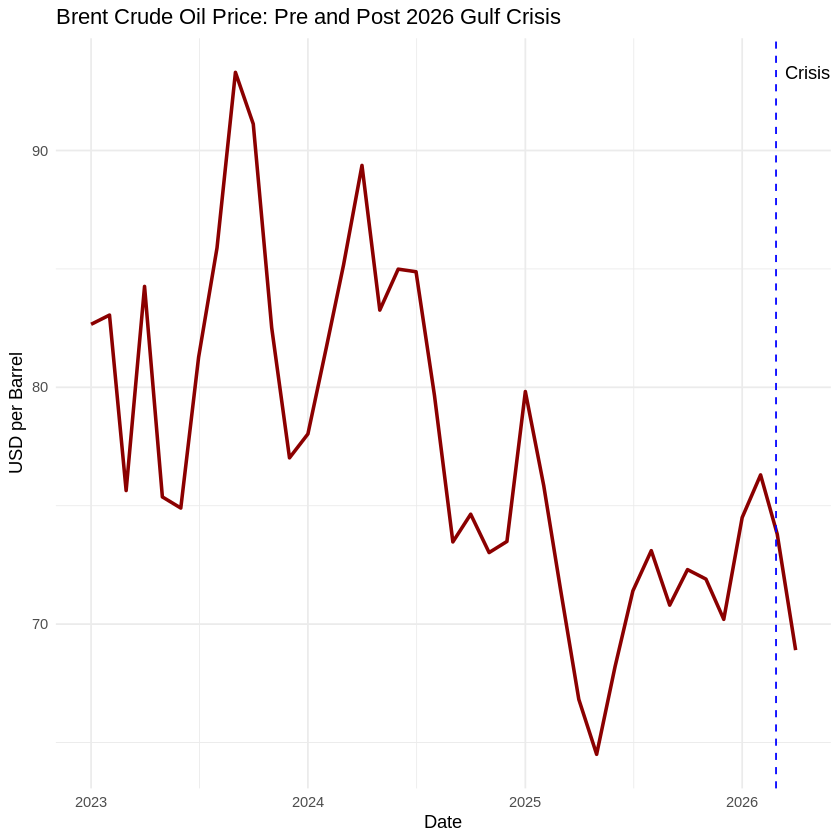


	Hausman Test

data:  ln_cpi ~ oil_pct_change + ln_neer + policy_rate + vix + post_crisis
chisq = 11.148, df = 5, p-value = 0.04852
alternative hypothesis: one model is inconsistent


	Lagrange Multiplier Test - (Breusch-Pagan)

data:  ln_cpi ~ oil_pct_change + ln_neer + policy_rate + vix + post_crisis
chisq = 3474.1, df = 1, p-value < 2.2e-16
alternative hypothesis: significant effects


--- Robust Standard Errors: Fixed Effects ---



t test of coefficients:

                  Estimate  Std. Error  t value  Pr(>|t|)    
oil_pct_change  0.00118819  0.00031556   3.7654 0.0001993 ***
ln_neer        -1.21946252  0.11572565 -10.5375 < 2.2e-16 ***
policy_rate     0.00348353  0.00123893   2.8117 0.0052450 ** 
vix             0.00497104  0.00102565   4.8467 1.996e-06 ***
post_crisis     0.05344488  0.01867000   2.8626 0.0044907 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



--- Robust Standard Errors: Random Effects ---



t test of coefficients:

                  Estimate  Std. Error  t value  Pr(>|t|)    
(Intercept)    10.38858817  0.56921584  18.2507 < 2.2e-16 ***
oil_pct_change  0.00119495  0.00031045   3.8491 0.0001436 ***
ln_neer        -1.21145567  0.11859207 -10.2153 < 2.2e-16 ***
policy_rate     0.00359522  0.00129210   2.7825 0.0057213 ** 
vix             0.00498651  0.00101848   4.8960 1.567e-06 ***
post_crisis     0.05364375  0.01837255   2.9198 0.0037562 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



--- Robust Standard Errors: Pooled OLS ---



t test of coefficients:

                 Estimate Std. Error t value  Pr(>|t|)    
(Intercept)     6.8310587  2.3319299  2.9294 0.0036453 ** 
oil_pct_change  0.0039863  0.0010408  3.8301 0.0001547 ***
ln_neer        -0.4815179  0.4999319 -0.9632 0.3362049    
policy_rate     0.0499808  0.0316594  1.5787 0.1154112    
vix             0.0107254  0.0022286  4.8125 2.319e-06 ***
post_crisis     0.1163696  0.0348581  3.3384 0.0009440 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



Main Regression Results: Log CPI
                         Dependent variable:          
               ---------------------------------------
                               ln_cpi                 
               Pooled OLS Fixed Effects Random Effects
                  (1)          (2)           (3)      
------------------------------------------------------
oil_pct_change   0.004       0.001**       0.001**    
                (0.004)      (0.001)       (0.001)    
                                                      
ln_neer        -0.482***    -1.219***     -1.211***   
                (0.057)      (0.033)       (0.033)    
                                                      
policy_rate     0.050***    0.003***       0.004***   
                (0.004)      (0.001)       (0.001)    
                                                      
vix              0.011      0.005***       0.005***   
                (0.007)      (0.001)       (0.001)    
                               

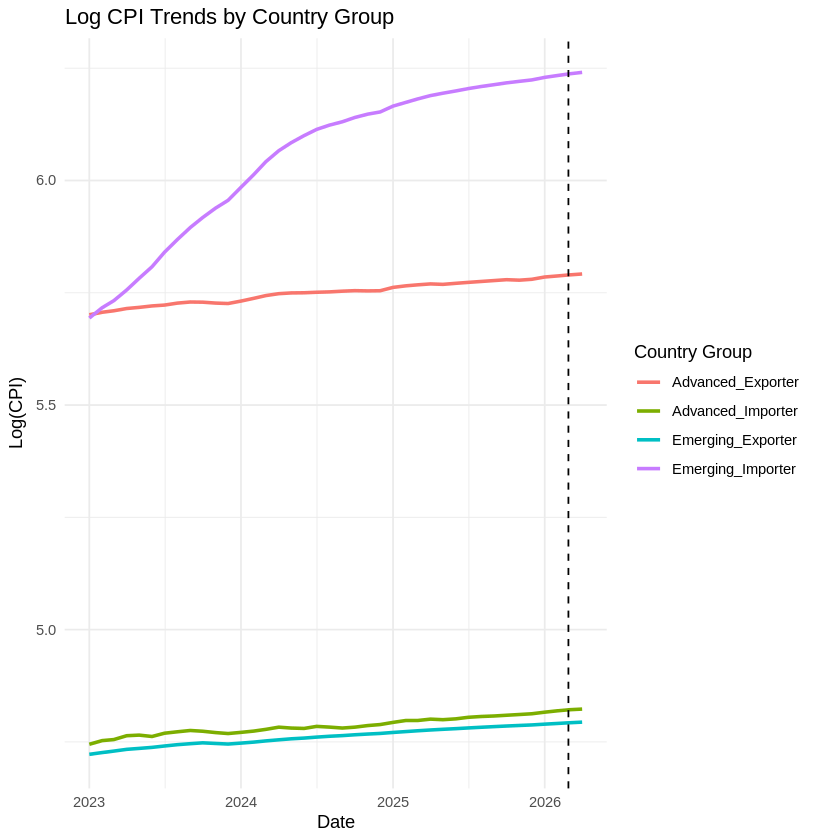

In [ ]:
# =====================
# R Code for the Project 
# =====================

# ============================================================================
# Project: Geopolitics, Oil Shock, and Macroeconomics - Panel Data Analysis
# ============================================================================

# 1. INSTALL AND LOAD LIBRARIES
# install.packages(c("tidyverse", "plm", "lmtest", "stargazer", "ggplot2", "car", "readxl"))

library(tidyverse)
library(plm)
library(lmtest)
library(stargazer)
library(ggplot2)
library(car)
library(readxl)

# ============================================================================
# 2. LOAD AND PREPARE THE DATA
# ============================================================================

# Read the EXCEL file, skipping the first row of broad category headers
data_raw <- read_excel("panel-dataset-gulf-crisis-research.xlsx", sheet = "Panel Data", skip = 1)

# Rename columns to match standard R naming conventions
data_raw <- data_raw %>%
  rename(
    country = Country,
    group = `Country Group`,
    oil_balance = `Oil Balance`,
    date = Date,
    year = Year,
    month = Month,
    brent = `Brent (USD/bbl)`,
    cpi = CPI,
    ipi = IPI,
    neer = NEER,
    policy_rate = `Policy Rate (%)`,
    vix = VIX
  )

# Ensure date column is in Date format
data_raw$date <- as.Date(data_raw$date)

# Create variables.
# NOTE: We use diff() instead of lag() because plm masks lag() and breaks it!
data_processed <- data_raw %>%
  group_by(country) %>%
  arrange(date) %>% # Ensure dates are chronological per country
  mutate(
    ln_cpi = log(cpi),
    ln_ipi = log(ipi),
    ln_neer = log(neer),
    # Create a dummy variable for the "post-crisis" period (starting March 2026)
    post_crisis = ifelse(date >= as.Date("2026-03-01"), 1, 0),
    # Calculate the monthly percentage change in oil price using diff()
    # diff() returns N-1 elements, so we prepend 0 for the first month
    oil_pct_change = c(0, diff(brent) / head(brent, -1) * 100)
  ) %>%
  ungroup() %>%
  filter(!is.na(ln_cpi), !is.na(ln_ipi), !is.na(oil_pct_change))

# ============================================================================
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================================

# Plot the trend of oil prices over time
ggplot(data_processed, aes(x = date, y = brent)) +
  geom_line(color = "darkred", linewidth = 1) +
  geom_vline(xintercept = as.numeric(as.Date("2026-02-27")), linetype = "dashed", color = "blue") +
  annotate("text", x = as.Date("2026-02-27"), y = max(data_processed$brent), label = "Crisis Start", hjust = -0.1) +
  labs(title = "Brent Crude Oil Price: Pre and Post 2026 Gulf Crisis",
       x = "Date", y = "USD per Barrel") +
  theme_minimal()

# Plot the average CPI trend for different country groups
ggplot(data_processed, aes(x = date, y = ln_cpi, color = group)) +
  stat_summary(fun = mean, geom = "line", linewidth = 1) +
  geom_vline(xintercept = as.numeric(as.Date("2026-02-27")), linetype = "dashed") +
  labs(title = "Log CPI Trends by Country Group",
       x = "Date", y = "Log(CPI)",
       color = "Country Group") +
  theme_minimal()

# ============================================================================
# 4. PANEL DATA REGRESSION ANALYSIS
# ============================================================================

# Declare the data as a panel data frame
pdata <- pdata.frame(data_processed, index = c("country", "date"))

# ----------------------------------------------------------------------------
# Model 1: Pooled OLS (POLS)
# ----------------------------------------------------------------------------
pols_model <- plm(ln_cpi ~ oil_pct_change + ln_neer + policy_rate + vix + post_crisis,
                  data = pdata,
                  model = "pooling")

# ----------------------------------------------------------------------------
# Model 2: Fixed Effects (FE) Model
# ----------------------------------------------------------------------------
fe_model <- plm(ln_cpi ~ oil_pct_change + ln_neer + policy_rate + vix + post_crisis,
                data = pdata,
                model = "within")

# ----------------------------------------------------------------------------
# Model 3: Random Effects (RE) Model
# ----------------------------------------------------------------------------
re_model <- plm(ln_cpi ~ oil_pct_change + ln_neer + policy_rate + vix + post_crisis,
                data = pdata,
                model = "random")

# ============================================================================
# 5. DIAGNOSTIC TESTS AND ROBUST STANDARD ERRORS
# ============================================================================

# 1. Hausman Test: FE vs RE
hausman_test <- phtest(fe_model, re_model)
print(hausman_test)

# 2. Breusch-Pagan Test: POLS vs RE
bp_test <- plmtest(pols_model, effect = "individual", type = "bp")
print(bp_test)

# 3. Robust Standard Errors (Arellano)
cat("\n--- Robust Standard Errors: Fixed Effects ---\n")
coeftest(fe_model, vcov = vcovHC(fe_model, method = "arellano", type = "HC3"))

cat("\n--- Robust Standard Errors: Random Effects ---\n")
coeftest(re_model, vcov = vcovHC(re_model, method = "arellano", type = "HC3"))

cat("\n--- Robust Standard Errors: Pooled OLS ---\n")
coeftest(pols_model, vcov = vcovHC(pols_model, type = "HC3"))

# ============================================================================
# 6. HETEROGENEITY ANALYSIS: OIL-IMPORTERS VS. EXPORTERS
# ============================================================================

# Run FE models for each subgroup directly from the processed data
fe_importers <- plm(ln_cpi ~ oil_pct_change + ln_neer + policy_rate + vix + post_crisis,
                    data = data_processed %>% filter(oil_balance == "importer"),
                    model = "within",
                    index = c("country", "date"))

fe_exporters <- plm(ln_cpi ~ oil_pct_change + ln_neer + policy_rate + vix + post_crisis,
                    data = data_processed %>% filter(oil_balance == "exporter"),
                    model = "within",
                    index = c("country", "date"))

# ============================================================================
# 7. ROBUSTNESS CHECK: EXCLUDING TURKEY
# ============================================================================
# Turkey's hyperinflation skews the Emerging_Importer group.
# We exclude it to see the true effect on normal importers.

data_no_turkey <- data_processed %>% filter(country != "Turkey")

fe_importers_no_turkey <- plm(ln_cpi ~ oil_pct_change + ln_neer + policy_rate + vix + post_crisis,
                              data = data_no_turkey %>% filter(oil_balance == "importer"),
                              model = "within",
                              index = c("country", "date"))

# ============================================================================
# 8. FINAL REGRESSION TABLES
# ============================================================================

# Table 1: Main Models Comparison
stargazer(pols_model, fe_model, re_model,
          title = "Main Regression Results: Log CPI",
          column.labels = c("Pooled OLS", "Fixed Effects", "Random Effects"),
          type = "text",
          keep.stat = c("n", "rsq"))

# Table 2: Heterogeneity & Robustness
stargazer(fe_importers, fe_exporters, fe_importers_no_turkey,
          title = "Fixed Effects: Importers vs. Exporters (with Turkey Robustness Check)",
          column.labels = c("Importers (All)", "Exporters", "Importers (Excl. Turkey)"),
          type = "text",
          keep.stat = c("n", "rsq"))